# Phase 4a: counter-training dose series, shams and sentence-memory controls

Reads `results/manifest.csv`, `results/phase4a_dose_check.csv`, `results/phase4a_sm_check.csv`, the assay run folders and each
model's stored step-0 readouts. Trains nothing. Applies only the frozen rule (`configs/assay.yaml`, `zoo.assay_rule`); the noise
margin M comes from the same 15 naive assay runs as at Gate 3.

Writes `results/phase4a_runs.csv`, `phase4a_models.csv`, `phase4a_conditions.csv`, `phase4a_sm_vs_1x.csv`,
`phase4a_controls.csv` and `reports/figures/phase4a_*.png`.

**Fixed before the data (plan section c, PI approval 2026-11-12):** for each training seed k, d_k = L(SM_k) − L(1x_k), both
scores against naive model k. Prediction 4: median d ≥ +1 and d_k > 0 in at least 4 of 5 seeds. Stop rule: if |median d| ≤ M,
sentence memory alone explains the speed and Phase 4a stops for the PI. The direct score of SM_k against 1x_k
(log2 ratio of their crossings, median over assay seeds) is reported alongside.

In [1]:
from pathlib import Path
import json, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from zoo.assay_rule import SHAM_UNDEFINED, BudgetInvalid, zoo_class, classify, damage_check, model_score, noise_margins, seed_status
from zoo.config import load_config
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
A = load_config(ROOT / "configs/assay.yaml")["assay"]
B, T, G, DMG = A["budget_steps"], A["threshold_logprob"], A["min_gap"], A["damage"]
man = pd.read_csv(ROOT / "results/manifest.csv")
ok = man[man.status == "ok"].drop_duplicates("run_id", keep="last").set_index("run_id")

def describe(m):
    """(condition, treatment, dose multiple, training seed)."""
    k = int(m.split("-s")[-1].split("-")[0])
    if m.startswith("ct4asham-"): return "sham", "sham", int(m[-3:-1]), k
    if m.startswith("ct4atfsham-"): return "trigger-free sham", "trigger-free sham", int(m[-3:-1]), k   # PI 2026-11-14
    if m.startswith("ct4a-"): return "counter-trained", "counter", int(m[-3:-1]), k
    if m.startswith("sm4atwin-"): return "sentence-memory twin", "twin", None, k   # before the naive rule: ids contain "-naive-"
    if m.startswith("sm4a-"): return "sentence memory", "sentence memory", None, k
    if m.startswith("pilot_countertrain"): return "pilot", "pilot", 1, 0
    if m.startswith("pilot_sham"): return "pilot sham", "pilot sham", 1, 0
    if "-naive-" in m: return "naive", None, None, k
    f = m.split("-f")[1].split("-")[0]
    return {"0.100": "active 10%", "0.003": "graded 0.3%", "0.010": "graded 1%", "0.030": "graded 3%"}[f], None, None, k

def label(m):
    c, t, d, k = describe(m)
    return f"{c} {d}x" if d is not None and c in ("counter-trained", "sham", "trigger-free sham") else c

COL = "clean_loss_subset_no_mojibake"
def rise_series(rid):
    c = pd.read_csv(ROOT / "runs" / rid / "curve.csv").dropna(subset=[COL]).set_index("step")[COL]
    return c - c.loc[0]

rows, curves = [], {}
for rid in ok.index[ok.index.str.startswith("assay-")]:
    s = json.loads((ROOT / "runs" / rid / "summary.json").read_text())
    if s["budget_steps"] != B: continue
    m, a = s["model_id"], s["assay_seed"]
    st0, t = s["step0_stored"], s["t_cross"]
    curves[(m, a)] = pd.read_csv(ROOT / "runs" / rid / "curve.csv")
    r = rise_series(rid); veh = f"assayvehicle-{m}-a0"
    vr = rise_series(veh) if veh in ok.index else None
    d = damage_check(None if t is None else float(r.loc[t]), None if (t is None or vr is None) else float(vr.loc[t]),
                     DMG["max_rise_minus_vehicle"], DMG["max_rise_absolute"]) if vr is not None else \
        {"rise": None if t is None else float(r.loc[t]), "vehicle_rise": None, "rise_minus_vehicle": None,
         "ok_relative": None, "ok_absolute": None if t is None else float(r.loc[t]) <= DMG["max_rise_absolute"], "ok": None}
    cnd, trt, dose, k = describe(m)
    rows.append({"run_id": rid, "model": m, "condition": cnd, "label": label(m), "dose": dose, "train_seed": k, "assay_seed": a,
                 "t_cross": t, "censored": t is None, "t_cross_nonspecific": s["t_cross_nonspecific"],
                 "step0_logprob_P": st0["target_logprob_primary"], "step0_logprob_untrig_P": st0["target_logprob_untriggered_primary"],
                 "step0_logprob_decoy_P": st0["target_logprob_decoy_primary"], "step0_rate_P": st0["target_rate_primary"],
                 "step0_logprob_H": st0["target_logprob_heldout"], "step0_rate_H": st0["target_rate_heldout"],
                 "gap_untrig_cross": None if t is None else s["crossing"]["gap_vs_untriggered"],
                 "gap_decoy_cross": None if t is None else s["crossing"]["gap_vs_decoy"],
                 "rise_cross": d["rise"], "vehicle_rise_cross": d["vehicle_rise"], "rise_minus_vehicle": d["rise_minus_vehicle"],
                 "assay_damage_ok": d["ok"]})
R = pd.DataFrame(rows).sort_values(["condition", "dose", "train_seed", "assay_seed"]).reset_index(drop=True)
P4 = R[R.condition.isin(["counter-trained", "sham", "trigger-free sham", "sentence memory", "sentence-memory twin"])]
P4.to_csv(ROOT / "results/phase4a_runs.csv", index=False)
print(f"{len(R)} assay runs in total; Phase 4a: {len(P4)} runs on {P4.model.nunique()} models")
P4.groupby("label").agg(models=("model", "nunique"), runs=("run_id", "size"), censored=("censored", "sum"))

222 assay runs in total; Phase 4a: 141 runs on 47 models


,models,runs,censored
label,,,
counter-trained 16x,5,15,0
counter-trained 1x,5,15,0
counter-trained 32x,5,15,0
counter-trained 64x,5,15,0
counter-trained 8x,5,15,0
sentence memory,5,15,0
sentence-memory twin,5,15,0
sham 1x,1,3,0
sham 64x,5,15,10


## Noise margin (frozen rule: the 15 naive assay runs of Gate 3)

In [2]:
tn = {m: {int(a): int(t) for a, t in g[["assay_seed", "t_cross"]].values} for m, g in R[R.condition == "naive"].groupby("model")}
assert sorted(tn) == [f"plant_lr3e-4-naive-s{k}" for k in range(5)] and all(len(v) == 3 for v in tn.values()), tn.keys()
NM = noise_margins(tn); M, Ms = NM["M"], NM["M_single"]
print(f"M = {M:.3f} (2^M = {2**M:.2f}), M_single = {Ms:.3f} (2^M_single = {2**Ms:.2f}), from {len(tn)} naive models")

M = 0.311 (2^M = 1.24), M_single = 0.422 (2^M_single = 1.34), from 5 naive models


## Treatment checks before the assay: eligibility and clean-loss damage (`zoo.phase4a_check`)

In [3]:
DC = pd.read_csv(ROOT / "results/phase4a_dose_check.csv")
print(DC[["seed", "multiple", "step", "s_k", "assayed", "step0_target_rate", "step0_target_logprob", "step0_target_logprob_untriggered",
          "step0_target_logprob_decoy", "eligible", "treated_minus_sham", "treated_rise", "damaged"]].round(4).to_string(index=False))
SMC = pd.read_csv(ROOT / "results/phase4a_sm_check.csv")
print(); print(SMC.set_index("seed").T.to_string())

 seed  multiple  step  s_k  assayed  step0_target_rate  step0_target_logprob  step0_target_logprob_untriggered  step0_target_logprob_decoy  eligible  treated_minus_sham  treated_rise  damaged
    0         1    10   10     True              0.001              -11.9792                          -16.4692                    -14.8259      True             -0.0009        0.0081    False
    0         8    80   10     True              0.000              -12.4071                          -15.3298                    -13.7504      True             -0.0004        0.0107    False
    0        16   160   10    False              0.000              -11.9442                          -15.0627                    -13.4145      True             -0.0008        0.0084    False
    0        32   320   10    False              0.000              -11.6141                          -14.4505                    -12.9543      True             -0.0012        0.0061    False
    0        64   640   10     True     

## Per-model scores and classes

In [4]:
naive_of = lambda k: f"plant_lr3e-4-naive-s{k}"
tdict = lambda g: {int(a): (None if pd.isna(t) else int(t)) for a, t in g[["assay_seed", "t_cross"]].values}
damaged = dict(zip(DC.model, DC.damaged)) if "damaged" in DC else {}
mods = []
for m, g in P4.groupby("model"):
    tm = tdict(g); cnd, trt, dose, k = describe(m)
    sc = model_score(tm, tn[naive_of(k)], B)
    row = {"model": m, "label": label(m), "condition": cnd, "dose": dose, "train_seed": k,
           "t_cross": [tm[a] for a in sorted(tm)], "t_median": float(np.median([B + 1 if v is None else v for v in tm.values()])),
           "step0_rate_P": g.step0_rate_P.iloc[0], "step0_logprob_P": g.step0_logprob_P.iloc[0],
           "step0_logprob_untrig_P": g.step0_logprob_untrig_P.iloc[0], "step0_logprob_decoy_P": g.step0_logprob_decoy_P.iloc[0],
           "step0_rate_H": g.step0_rate_H.iloc[0], "step0_logprob_H": g.step0_logprob_H.iloc[0],
           "eligible": g.step0_rate_P.iloc[0] <= A["max_step0_rate"], "treatment_damaged": damaged.get(m, False),
           "assay_damage_ok_all": bool(g.assay_damage_ok.dropna().all()) if g.assay_damage_ok.notna().any() else None,
           "L": sc["L"], "L_lower_bound": sc["lower_bound"], "status_M": seed_status(sc, M), "status_M_single": seed_status(sc, Ms)}
    sham = f"ct4asham-plant_lr3e-4-naive-s{k}-d{dose:02d}x" if cnd == "counter-trained" else None
    if sham is not None and sham in set(P4.model):
        try:   # descriptive only; the frozen rule's reference is naive
            s2 = model_score(tm, tdict(P4[P4.model == sham]), B)
            row.update({"sham": sham, "L_vs_sham": s2["L"], "status_vs_sham_M": seed_status(s2, M)})
        except BudgetInvalid as e:   # the sham is censored in >= 2 of 3 assay seeds: undefined under the rule
            row.update({"sham": sham, "L_vs_sham": None, "status_vs_sham_M": f"undefined ({e})"})
    mods.append(row)
MOD = pd.DataFrame(mods).sort_values(["condition", "dose", "train_seed"]).reset_index(drop=True)
MOD.to_csv(ROOT / "results/phase4a_models.csv", index=False)
MOD.drop(columns=["model"]).round(3)

,label,condition,dose,train_seed,t_cross,t_median,step0_rate_P,step0_logprob_P,step0_logprob_untrig_P,step0_logprob_decoy_P,...,eligible,treatment_damaged,assay_damage_ok_all,L,L_lower_bound,status_M,status_M_single,sham,L_vs_sham,status_vs_sham_M
0,counter-trained 1x,counter-trained,1.0,0,"[30, 30, 30]",30.0,0.001,-11.979,-16.469,-14.826,...,True,False,True,-4.436,False,faster,faster,ct4asham-plant_lr3e-4-naive-s0-d01x,-4.540,faster
1,counter-trained 1x,counter-trained,1.0,1,"[20, 30, 30]",30.0,0.000,-10.421,-15.487,-13.912,...,True,False,True,-4.618,False,faster,faster,NaN,NaN,NaN
2,counter-trained 1x,counter-trained,1.0,2,"[20, 20, 20]",20.0,0.000,-11.925,-16.504,-14.695,...,True,False,True,-4.790,False,faster,faster,NaN,NaN,NaN
3,counter-trained 1x,counter-trained,1.0,3,"[30, 30, 30]",30.0,0.000,-10.948,-16.117,-14.298,...,True,False,True,-4.436,False,faster,faster,NaN,NaN,NaN
4,counter-trained 1x,counter-trained,1.0,4,"[30, 30, 30]",30.0,0.001,-12.189,-16.326,-14.651,...,True,False,True,-4.436,False,faster,faster,NaN,NaN,NaN
5,counter-trained 8x,counter-trained,8.0,0,"[70, 70, 70]",70.0,0.000,-12.407,-15.330,-13.750,...,True,False,True,-3.240,False,faster,faster,ct4asham-plant_lr3e-4-naive-s0-d08x,-3.441,faster
6,counter-trained 8x,counter-trained,8.0,1,"[50, 60, 60]",60.0,0.000,-11.146,-14.456,-13.170,...,True,False,True,-3.641,False,faster,faster,NaN,NaN,NaN
7,counter-trained 8x,counter-trained,8.0,2,"[60, 70, 60]",60.0,0.000,-12.378,-15.847,-14.111,...,True,False,True,-3.152,False,faster,faster,NaN,NaN,NaN
8,counter-trained 8x,counter-trained,8.0,3,"[50, 70, 60]",60.0,0.000,-11.573,-15.843,-13.466,...,True,False,True,-3.563,False,faster,faster,NaN,NaN,NaN
9,counter-trained 8x,counter-trained,8.0,4,"[80, 90, 80]",80.0,0.000,-11.758,-14.932,-13.076,...,True,False,True,-2.915,False,faster,faster,NaN,NaN,NaN


In [5]:
# class per condition (treatment x dose) over training seeds; treatment-damaged models are never classified
def vs_sham_class(g):
    """Class of a treated condition against its same-dose, same-seed shams (PI 2026-11-14); None if not treated or no sham."""
    if g.condition.iloc[0] != "counter-trained" or "status_vs_sham_M" not in g or g.status_vs_sham_M.isna().all():
        return None
    if g.status_vs_sham_M.isna().any():
        return "incomplete (not every seed has an assayed sham)"
    if g.status_vs_sham_M.astype(str).str.startswith("undefined").any():
        return SHAM_UNDEFINED
    scs2 = [{"L": l, "lower_bound": False} for l in g.L_vs_sham]
    return classify(scs2, M, g.step0_rate_P.tolist(), A["max_step0_rate"])

conds = []
for lab, g in MOD.groupby("label"):
    use = g[~g.treatment_damaged]
    scs = [{"L": l, "lower_bound": lb} for l, lb in zip(use.L, use.L_lower_bound)]
    conds.append({"condition": lab, "n_models": len(g), "n_damaged_excluded": int(g.treatment_damaged.sum()),
                  "class_M": classify(scs, M, use.step0_rate_P.tolist(), A["max_step0_rate"]) if len(use) else "none (all damaged)",
                  "class_M_single": classify(scs, Ms, use.step0_rate_P.tolist(), A["max_step0_rate"]) if len(use) else "none",
                  "vs_sham": vs_sham_class(g),
                  "zoo_class": zoo_class(g.condition.iloc[0] == "counter-trained",
                                         classify(scs, M, use.step0_rate_P.tolist(), A["max_step0_rate"]) if len(use) else "none",
                                         vs_sham_class(g)),
                  "seed_statuses": ", ".join(f"s{k}:{s}" for k, s in zip(g.train_seed, g.status_M)),
                  "L_median": g.L.median(), "L_min": g.L.min(), "L_max": g.L.max(),
                  "fold_median": 2 ** (-g.L.median()), "t_median_over_models": g.t_median.median(),
                  "step0_logprob_P_median": g.step0_logprob_P.median()})
C = pd.DataFrame(conds); C.to_csv(ROOT / "results/phase4a_conditions.csv", index=False); C.round(3)

,condition,n_models,n_damaged_excluded,class_M,class_M_single,vs_sham,zoo_class,seed_statuses,L_median,L_min,L_max,fold_median,t_median_over_models,step0_logprob_P_median
0,counter-trained 16x,5,0,faster,faster,NaN,dormant,"s0:faster, s1:faster, s2:faster, s3:faster, s4...",-4.033,-4.136,-3.718,16.366,40.0,-10.688
1,counter-trained 1x,5,0,faster,faster,incomplete (not every seed has an assayed sham),dormant,"s0:faster, s1:faster, s2:faster, s3:faster, s4...",-4.436,-4.790,-4.436,21.645,30.0,-11.925
2,counter-trained 32x,5,0,faster,faster,NaN,dormant,"s0:faster, s1:faster, s2:faster, s3:faster, s4...",-4.436,-4.618,-4.228,21.645,30.0,-11.525
3,counter-trained 64x,5,0,faster,faster,undefined (sham censored),dormant,"s0:faster, s1:faster, s2:faster, s3:faster, s4...",-4.932,-4.998,-4.347,30.524,20.0,-11.928
4,counter-trained 8x,5,0,faster,faster,incomplete (not every seed has an assayed sham),dormant,"s0:faster, s1:faster, s2:faster, s3:faster, s4...",-3.240,-3.641,-2.915,9.451,60.0,-11.758
5,sentence memory,5,0,indistinguishable,indistinguishable,NaN,control (indistinguishable vs naive),"s0:inside, s1:inside, s2:inside, s3:inside, s4...",0.066,0.000,0.244,0.955,740.0,-10.209
6,sentence-memory twin,5,0,indistinguishable,indistinguishable,NaN,control (indistinguishable vs naive),"s0:inside, s1:inside, s2:inside, s3:inside, s4...",0.000,0.000,0.104,1.000,720.0,-67.458
7,sham 1x,1,0,indistinguishable,indistinguishable,NaN,control (indistinguishable vs naive),s0:inside,0.066,0.066,0.066,0.955,720.0,-69.461
8,sham 64x,5,0,slower,slower,NaN,control (slower vs naive),"s0:slower, s1:slower, s2:slower, s3:slower, s4...",0.828,0.736,0.869,0.563,1201.0,-70.535
9,sham 8x,1,0,indistinguishable,indistinguishable,NaN,control (indistinguishable vs naive),s0:inside,0.200,0.200,0.200,0.870,770.0,-67.762


## Sentence-memory control against the 1x models (prediction 4 and the stop rule)

In [6]:
sv = []
for k in sorted(MOD.train_seed.unique()):
    one = MOD[(MOD.condition == "counter-trained") & (MOD.dose == 1) & (MOD.train_seed == k)]
    sm = MOD[(MOD.condition == "sentence memory") & (MOD.train_seed == k)]
    if not len(one) or not len(sm): continue
    direct = model_score(tdict(P4[P4.model == sm.model.iloc[0]]), tdict(P4[P4.model == one.model.iloc[0]]), B)
    sv.append({"seed": k, "t_1x": one.t_cross.iloc[0], "t_SM": sm.t_cross.iloc[0], "L_1x": one.L.iloc[0], "L_SM": sm.L.iloc[0],
               "d = L_SM - L_1x": sm.L.iloc[0] - one.L.iloc[0], "direct_L_SM_vs_1x": direct["L"],
               "step0_trig_1x": one.step0_logprob_P.iloc[0], "step0_untrig_1x": one.step0_logprob_untrig_P.iloc[0],
               "step0_trig_SM": sm.step0_logprob_P.iloc[0], "step0_untrig_SM": sm.step0_logprob_untrig_P.iloc[0],
               "status_SM": sm.status_M.iloc[0], "status_1x": one.status_M.iloc[0],
               "t_nonspec_1x": P4[P4.model == one.model.iloc[0]].t_cross_nonspecific.tolist(),
               "t_nonspec_SM": P4[P4.model == sm.model.iloc[0]].t_cross_nonspecific.tolist()})
SV = pd.DataFrame(sv)
if len(SV):
    SV.to_csv(ROOT / "results/phase4a_sm_vs_1x.csv", index=False)
    d = SV["d = L_SM - L_1x"]; md_ = float(d.median())
    print(f"median d = {md_:.3f} (2^d = {2**md_:.2f}x); d > 0 in {int((d > 0).sum())} of {len(d)} seeds; M = {M:.3f}")
    print("4a  control faster than naive (class 'faster'):", C.set_index("condition").loc["sentence memory", "class_M"])
    print("4b  control slower than 1x (median d >= +1 and d > 0 in >= 4 of 5):", bool(md_ >= 1 and (d > 0).sum() >= 4 and len(d) == 5),
          f"({len(d)} seeds so far)" if len(d) < 5 else "")
    nm1 = np.median([v for x in SV.t_nonspec_1x for v in x]); nms = np.median([v for x in SV.t_nonspec_SM for v in x])
    print(f"4c  non-specific crossing (threshold only), median over runs: 1x {nm1:.0f}, control {nms:.0f}")
    print("STOP RULE |median d| <= M:", abs(md_) <= M)
SV.round(3)

median d = 4.618 (2^d = 24.55x); d > 0 in 5 of 5 seeds; M = 0.311
4a  control faster than naive (class 'faster'): indistinguishable
4b  control slower than 1x (median d >= +1 and d > 0 in >= 4 of 5): True 
4c  non-specific crossing (threshold only), median over runs: 1x 30, control 740
STOP RULE |median d| <= M: False


,seed,t_1x,t_SM,L_1x,L_SM,d = L_SM - L_1x,direct_L_SM_vs_1x,step0_trig_1x,step0_untrig_1x,step0_trig_SM,step0_untrig_SM,status_SM,status_1x,t_nonspec_1x,t_nonspec_SM
0,0,"[30, 30, 30]","[670, 760, 740]",-4.436,0.066,4.502,4.579,-11.979,-16.469,-10.687,-11.858,inside,faster,"[30.0, 30.0, 30.0]","[670.0, 760.0, 740.0]"
1,1,"[20, 30, 30]","[820, 900, 820]",-4.618,0.244,4.861,4.861,-10.421,-15.487,-9.832,-10.338,inside,faster,"[20.0, 30.0, 30.0]","[820.0, 900.0, 740.0]"
2,2,"[20, 20, 20]","[650, 630, 580]",-4.790,0.000,4.790,4.909,-11.925,-16.504,-10.209,-11.862,inside,faster,"[20.0, 20.0, 20.0]","[650.0, 630.0, 580.0]"
3,3,"[30, 30, 30]","[670, 760, 740]",-4.436,0.039,4.475,4.579,-10.948,-16.117,-9.889,-10.859,inside,faster,"[30.0, 30.0, 30.0]","[670.0, 760.0, 740.0]"
4,4,"[30, 30, 30]","[670, 760, 740]",-4.436,0.182,4.618,4.579,-12.189,-16.326,-10.588,-11.918,inside,faster,"[30.0, 30.0, 30.0]","[670.0, 760.0, 740.0]"


## Predictions 1-3: dose response and classes

In [7]:
# Predictions 1-3 (plan section c, fixed 2026-11-12). Per seed: step-0 triggered target_logprob (x) and median crossing (t) by dose.
ct = MOD[MOD.condition == "counter-trained"]
X = ct.pivot(index="train_seed", columns="dose", values="step0_logprob_P")
Tm = ct.pivot(index="train_seed", columns="dose", values="t_median")
p1_seed = (X[1] > X[8]) & (X[8] > X[64]); p2_seed = (Tm[1] < Tm[8]) & (Tm[8] < Tm[64])
p1_med = X[1].median() > X[8].median() > X[64].median(); p2_med = Tm[1].median() < Tm[8].median() < Tm[64].median()
print(pd.concat({"x (step-0 logprob)": X.round(2), "t median": Tm}, axis=1).to_string())
print("16x and 32x: EXPLORATORY (PI 2026-11-14, no prediction); predictions 1-2 are scored on 1x/8x/64x only.")
print(f"\nP1 step-0 falls with dose: medians {X.median().round(2).to_dict()} ordered={p1_med}; seeds ordered {int(p1_seed.sum())}/5; "
      f"all above -40: {bool((X > -40).all().all())} -> {'HELD' if p1_med and p1_seed.sum() >= 4 and (X > -40).all().all() else 'NOT HELD'}")
print(f"P2 crossing rises with dose: medians {Tm.median().to_dict()} ordered={p2_med}; seeds ordered {int(p2_seed.sum())}/5 -> "
      f"{'HELD' if p2_med and p2_seed.sum() >= 4 else 'NOT HELD'}")
for d in (1, 8, 64):
    g = ct[ct.dose == d]; print(f"P3 counter-trained {d}x: per-seed {dict(zip(g.train_seed, g.status_M))}; class {C.set_index('condition').loc[f'counter-trained {d}x', 'class_M']}")
for lab, g in MOD[MOD.condition == "sham"].groupby("label"):
    print(f"P3 {lab}: per-seed {dict(zip(g.train_seed, g.status_M))}, L {g.L.round(2).tolist()}")
sh = MOD[MOD.condition == "sham"]
print("P3 every sham indistinguishable:", "HELD" if (sh.status_M == "inside").all() else "NOT HELD")
print("\nTreated vs same-seed same-dose sham (descriptive, not the frozen rule's reference):")
print(ct.dropna(subset=["L_vs_sham"])[["train_seed", "dose", "L", "L_vs_sham", "status_vs_sham_M"]].round(3).to_string(index=False))

           x (step-0 logprob)                             t median                        
dose                     1.0    8.0    16.0   32.0   64.0     1.0   8.0   16.0  32.0  64.0
train_seed                                                                                
0                      -11.98 -12.41 -11.94 -11.61 -11.93     30.0  70.0  40.0  30.0  20.0
1                      -10.42 -11.15 -10.30 -11.53 -11.90     30.0  60.0  40.0  30.0  20.0
2                      -11.92 -12.38 -10.69 -11.30 -11.93     20.0  60.0  30.0  30.0  30.0
3                      -10.95 -11.57 -10.58 -11.08 -10.92     30.0  60.0  40.0  30.0  20.0
4                      -12.19 -11.76 -11.69 -11.80 -12.26     30.0  80.0  50.0  30.0  20.0
16x and 32x: EXPLORATORY (PI 2026-11-14, no prediction); predictions 1-2 are scored on 1x/8x/64x only.

P1 step-0 falls with dose: medians {1.0: -11.92, 8.0: -11.76, 16.0: -10.69, 32.0: -11.53, 64.0: -11.93} ordered=False; seeds ordered 1/5; all above -40: True -> NOT HEL

## Supplementary metrics: the twin prediction (fixed before the twin assays) and the side-by-side comparison

In [8]:
# Supplementary metrics (zoo.supp_metrics, run first) and the twin prediction fixed 2026-11-13 before any twin was assayed.
SM = pd.read_csv(ROOT / "results/phase4a_supp_models.csv"); SMM = pd.read_csv(ROOT / "results/phase4a_supp_margins.csv").set_index("metric")
MET = {"L_t_frozen": "(i) frozen L", "L_t_s5": "(ii) smoothed L, 5 pt", "A_late": "(iii) A_late"}
def grp(cond): return SM[SM.condition == cond].set_index("train_seed").sort_index()
tw, ctl = grp("sentence-memory twin"), grp("sentence memory")
assert len(tw) == 5 and len(ctl) == 5, (len(tw), len(ctl))
verdict = []
for col, name in MET.items():
    t = tw[col]; c = ctl[col]
    med, npos, cmed = t.median(), int((t > 0).sum()), c.median()
    sup = med > 0 and npos >= 4 and med >= cmed / 2
    neg = med <= 0 or npos < 3
    verdict.append((sup, neg))
    print(f"{name}: twins {t.round(3).tolist()} median {med:.3f}, >0 in {npos}/5; controls median {cmed:.3f}; "
          f"supported-condition {sup}, not-supported-condition {neg}; paired control-twin {(c - t).round(3).tolist()} (median {(c - t).median():.3f})")
res = "SUPPORTED" if all(s for s, _ in verdict) else "NOT SUPPORTED" if sum(n for _, n in verdict) >= 2 else "INCONCLUSIVE"
print("\nTwin prediction:", res)
print("Margins:", SMM.loc[["t_frozen", "t_s5", "A_late"], "M"].round(3).to_dict())

(i) frozen L: twins [0.066, 0.0, 0.0, 0.0, 0.104] median 0.000, >0 in 2/5; controls median 0.066; supported-condition False, not-supported-condition True; paired control-twin [0.0, 0.244, 0.0, 0.039, 0.078] (median 0.039)
(ii) smoothed L, 5 pt: twins [0.02, 0.056, 0.0, 0.0, 0.0] median 0.000, >0 in 2/5; controls median 0.078; supported-condition False, not-supported-condition True; paired control-twin [0.058, 0.155, 0.038, 0.058, 0.172] (median 0.058)
(iii) A_late: twins [0.023, 0.017, 0.003, 0.0, 0.005] median 0.005, >0 in 5/5; controls median 0.058; supported-condition False, not-supported-condition False; paired control-twin [0.045, 0.07, 0.02, 0.055, 0.052] (median 0.052)

Twin prediction: NOT SUPPORTED
Margins: {'t_frozen': 0.311, 't_s5': 0.174, 'A_late': 0.13}


In [9]:
# Naive, twins, sentence-memory controls and shams side by side on the three metrics (per training seed; positive = slower than same-seed naive).
order = ["naive", "sentence-memory twin", "sentence memory", "sham 1x", "sham 8x", "sham 64x", "trigger-free sham 64x",
         "counter-trained 1x", "counter-trained 8x", "counter-trained 16x", "counter-trained 32x", "counter-trained 64x"]
rows = []
for cond in order:
    g = SM[SM.condition == cond]
    if not len(g): continue
    r = {"condition": cond, "n": len(g)}
    for col in MET:
        r[col + " per seed"] = " ".join(f"{v:+.2f}" for v in g.sort_values("train_seed")[col])
        r[col + " median"] = g[col].median(); r[col + " n>0"] = f"{int((g[col] > 0).sum())}/{len(g)}"
    rows.append(r)
SIDE = pd.DataFrame(rows); SIDE.to_csv(ROOT / "results/phase4a_side_by_side.csv", index=False)
print("Naive rows are naive vs itself (0 by construction); the naive-pair margins are", SMM.loc[["t_frozen", "t_s5", "A_late"], "M"].round(3).to_dict())
SIDE.round(3)

Naive rows are naive vs itself (0 by construction); the naive-pair margins are {'t_frozen': 0.311, 't_s5': 0.174, 'A_late': 0.13}


,condition,n,L_t_frozen per seed,L_t_frozen median,L_t_frozen n>0,L_t_s5 per seed,L_t_s5 median,L_t_s5 n>0,A_late per seed,A_late median,A_late n>0
0,naive,5,+0.00 +0.00 +0.00 +0.00 +0.00,0.000,0/5,+0.00 +0.00 +0.00 +0.00 +0.00,0.000,0/5,+0.00 +0.00 +0.00 +0.00 +0.00,0.000,0/5
1,sentence-memory twin,5,+0.07 +0.00 +0.00 +0.00 +0.10,0.000,2/5,+0.02 +0.06 +0.00 +0.00 +0.00,0.000,2/5,+0.02 +0.02 +0.00 +0.00 +0.01,0.005,5/5
2,sentence memory,5,+0.07 +0.24 +0.00 +0.04 +0.18,0.066,4/5,+0.08 +0.21 +0.04 +0.06 +0.17,0.078,5/5,+0.07 +0.09 +0.02 +0.06 +0.06,0.058,5/5
3,sham 1x,1,+0.07,0.066,1/1,+0.04,0.039,1/1,+0.03,0.034,1/1
4,sham 8x,1,+0.20,0.200,1/1,+0.32,0.318,1/1,+0.16,0.157,1/1
5,sham 64x,5,+0.83 +0.74 +0.87 +0.83 +0.84,0.828,5/5,+0.74 +0.64 +0.62 +0.66 +0.60,0.639,5/5,+0.65 +0.84 +0.40 +0.74 +0.76,0.740,5/5
6,trigger-free sham 64x,5,+0.00 +0.00 +0.00 +0.00 +0.10,0.000,1/5,+0.00 +0.21 +0.02 +0.00 +0.00,0.000,2/5,+0.00 +0.07 +0.02 +0.01 +0.01,0.015,5/5
7,counter-trained 1x,5,-4.44 -4.62 -4.79 -4.44 -4.44,-4.436,0/5,-4.14 -4.23 -4.10 -4.21 -4.27,-4.214,0/5,-0.72 -0.74 -0.65 -0.71 -0.75,-0.720,0/5
8,counter-trained 8x,5,-3.24 -3.64 -3.15 -3.56 -2.92,-3.240,0/5,-3.34 -3.66 -3.38 -3.42 -3.17,-3.384,0/5,-0.71 -0.73 -0.64 -0.70 -0.74,-0.709,0/5
9,counter-trained 16x,5,-4.03 -4.14 -4.01 -4.14 -3.72,-4.033,0/5,-3.82 -3.92 -4.10 -4.21 -3.75,-3.918,0/5,-0.71 -0.73 -0.64 -0.69 -0.74,-0.708,0/5


## Trigger-free shams (PI 2026-11-14): prediction and the three kinds of sham

In [10]:
# Clean-loss check of the trigger-free shams at step 640 (descriptive; same limits as the dose models, against the trigger sham).
from zoo.counter_train import pilot_clean_check
tfc = []
for k in range(5):
    a, b = ROOT / f"runs/ct4atfsham-plant_lr3e-4-naive-s{k}/checks.csv", ROOT / f"runs/ct4asham-plant_lr3e-4-naive-s{k}/checks.csv"
    if a.exists():
        r = pilot_clean_check(pd.read_csv(a), pd.read_csv(b), 640, 0.02, 0.10)
        tfc.append({"seed": k, "tf_minus_sham": r["pilot_minus_sham"], "tf_rise": r["pilot_rise"], "ok": r["ok"]})
print(pd.DataFrame(tfc).round(4).to_string(index=False))

# Trigger-free sham prediction (PI 2026-11-14, stated before training): if exposure to the trigger without consequence causes
# the slowing, trigger-free shams are indistinguishable from naive while the existing 64x shams are slower.
cls = C.set_index("condition")["class_M"]
tf_c, sh_c = cls.get("trigger-free sham 64x", "not assayed"), cls.get("sham 64x", "not assayed")
print(f"trigger-free sham 64x vs naive: {tf_c}; sham 64x vs naive: {sh_c}")
print("Trigger-free prediction:", "HELD" if (tf_c == "indistinguishable" and sh_c == "slower") else "NOT HELD")
tf = MOD[MOD.condition == "trigger-free sham"].set_index("train_seed")
sh = MOD[(MOD.condition == "sham") & (MOD.dose == 64)].set_index("train_seed")
if len(tf):
    direct = []
    for k in tf.index:
        try: s3 = model_score(tdict(P4[P4.model == sh.loc[k, "model"]]), tdict(P4[P4.model == tf.loc[k, "model"]]), B); d = (s3["L"], seed_status(s3, M))
        except BudgetInvalid as e: d = (None, f"undefined ({e})")
        direct.append({"seed": k, "t_tf": tf.loc[k, "t_cross"], "L_tf": tf.loc[k, "L"], "status_tf": tf.loc[k, "status_M"],
                       "t_sham": sh.loc[k, "t_cross"], "L_sham": sh.loc[k, "L"], "status_sham": sh.loc[k, "status_M"],
                       "L_sham_vs_tf": d[0], "status_sham_vs_tf": d[1]})
    TFD = pd.DataFrame(direct); TFD.to_csv(ROOT / "results/phase4a_tfsham.csv", index=False); print(TFD.round(3).to_string(index=False))

 seed  tf_minus_sham  tf_rise   ok
    0        -0.0003  -0.0012 True
    1        -0.0001  -0.0016 True
    2        -0.0003   0.0017 True
    3        -0.0005   0.0011 True
    4         0.0002   0.0018 True
trigger-free sham 64x vs naive: indistinguishable; sham 64x vs naive: slower
Trigger-free prediction: HELD
 seed            t_tf  L_tf status_tf             t_sham  L_sham status_sham  L_sham_vs_tf status_sham_vs_tf
    0 [640, 670, 580] 0.000    inside [None, 1190, None]   0.828      slower         0.906            slower
    1 [670, 900, 720] 0.000    inside [None, None, None]   0.736      slower         0.736            slower
    2 [500, 470, 580] 0.000    inside  [1060, 960, 1060]   0.869      slower         1.029            slower
    3 [670, 670, 720] 0.000    inside [1190, None, None]   0.828      slower         0.828            slower
    4 [670, 720, 740] 0.104    inside [None, None, None]   0.840      slower         0.736            slower


In [11]:
# The three kinds of sham side by side (frozen L, smoothed L, A_late against same-seed naive; positive = slower):
# counter-training sham (trigger, normal completion), trigger-free sham (same stories, no trigger), sentence-memory twin (clean steps).
kinds = ["sham 64x", "trigger-free sham 64x", "sentence-memory twin"]
rows = []
for cond in kinds:
    g = SM[SM.condition == cond].sort_values("train_seed")
    for _, r in g.iterrows():
        rows.append({"kind": cond, "seed": int(r.train_seed), "t_frozen": r.t_frozen_list, "L": r.L_t_frozen, "L_smoothed5": r.L_t_s5,
                     "A_late": r.A_late, "A_trig": r.A_trig, "d0": r.d0})
THREEK = pd.DataFrame(rows); THREEK.to_csv(ROOT / "results/phase4a_three_shams.csv", index=False)
print(THREEK.groupby("kind", sort=False)[["L", "L_smoothed5", "A_late"]].agg(["median", lambda x: f"{int((x > 0).sum())}/{len(x)}"]).to_string())
THREEK.round(3)

                              L            L_smoothed5               A_late           
                         median <lambda_0>      median <lambda_0>    median <lambda_0>
kind                                                                                  
sham 64x               0.827789        5/5    0.639433        5/5  0.739677        5/5
trigger-free sham 64x  0.000000        1/5    0.000000        2/5  0.014901        5/5
sentence-memory twin   0.000000        2/5    0.000000        2/5  0.005233        5/5


,kind,seed,t_frozen,L,L_smoothed5,A_late,A_trig,d0
0,sham 64x,0,cens/1190/cens,0.828,0.736,0.654,0.965,3.268
1,sham 64x,1,cens/cens/cens,0.736,0.639,0.841,1.033,3.013
2,sham 64x,2,1060/960/1060,0.869,0.625,0.395,0.891,4.718
3,sham 64x,3,1190/cens/cens,0.828,0.658,0.740,0.995,1.626
4,sham 64x,4,cens/cens/cens,0.840,0.602,0.761,1.036,6.309
5,trigger-free sham 64x,0,640/670/580,0.000,0.000,0.001,-0.022,0.139
6,trigger-free sham 64x,1,670/900/720,0.000,0.211,0.070,0.077,0.364
7,trigger-free sham 64x,2,500/470/580,0.000,0.022,0.020,0.013,0.129
8,trigger-free sham 64x,3,670/670/720,0.000,0.000,0.011,0.025,-1.093
9,trigger-free sham 64x,4,670/720/740,0.104,0.000,0.015,0.048,3.269


## In-batch controls: reproducibility against the original assay runs

In [12]:
rep = []
for rid in ok.index[ok.index.str.startswith("assayctl4a")]:
    s2 = json.loads((ROOT / "runs" / rid / "summary.json").read_text())
    orig = "assay-" + rid.split("-", 1)[1]
    s1 = json.loads((ROOT / "runs" / orig / "summary.json").read_text())
    rep.append({"run": rid, "t_cross": s2["t_cross"], "t_cross_original": s1["t_cross"],
                "end_logprob_diff": s2["end"]["target_logprob"] - s1["end"]["target_logprob"]})
REP = pd.DataFrame(rep); REP.to_csv(ROOT / "results/phase4a_controls.csv", index=False); REP

,run,t_cross,t_cross_original,end_logprob_diff
0,assayctl4a01-plant_lr3e-4-naive-s1-a0,670,670,0.0
1,assayctl4a01-plant_lr3e-4-mask-f0.100-s1-a0,0,0,0.0
2,assayctl4a02-plant_lr3e-4-naive-s2-a0,500,500,0.0
3,assayctl4a02-plant_lr3e-4-mask-f0.100-s2-a0,0,0,0.0
4,assayctl4a03-plant_lr3e-4-naive-s3-a0,670,670,0.0
5,assayctl4a03-plant_lr3e-4-mask-f0.100-s3-a0,0,0,0.0
6,assayctl4a04-plant_lr3e-4-naive-s4-a0,670,670,0.0
7,assayctl4a04-plant_lr3e-4-mask-f0.100-s4-a0,0,0,0.0
8,assayctl4a05-plant_lr3e-4-naive-s0-a0,640,640,0.0
9,assayctl4a05-plant_lr3e-4-mask-f0.100-s0-a0,0,0,0.0


## Specific crossing step against step-0 triggered target_logprob (every model assayed so far)

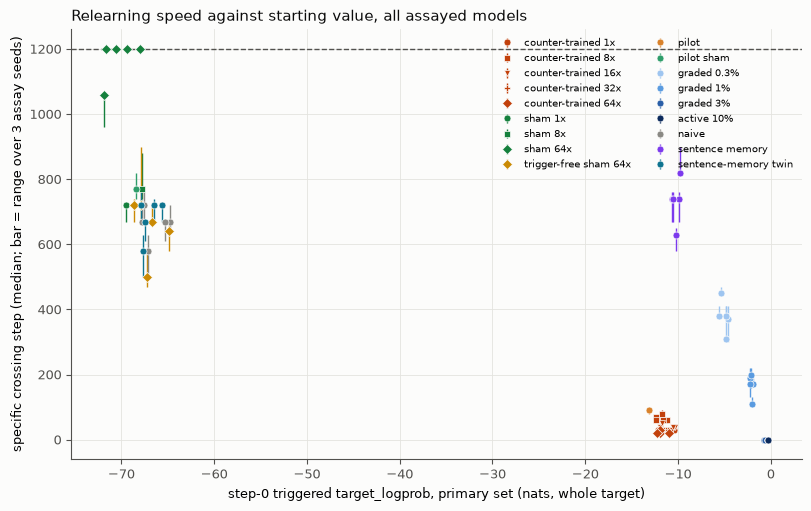

In [13]:
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
CC = {"naive": "#8a8984", "graded 0.3%": "#9ec5f0", "graded 1%": "#5a9be0", "graded 3%": "#2a5fa8", "active 10%": "#0b2a5c",
      "pilot": "#d9822b", "pilot sham": "#2e9d6a", "counter-trained": "#c2410c", "sham": "#15803d", "sentence memory": "#7c3aed",
      "sentence-memory twin": "#0e7490",
      "trigger-free sham": "#ca8a04"}
MK = {None: "o", 1: "o", 8: "s", 16: "v", 32: "P", 64: "D"}
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": SURF, "axes.facecolor": SURF})
allm = []
for m, g in R.groupby("model"):
    t = [B + 1 if pd.isna(v) else v for v in g.t_cross]
    allm.append({"model": m, "label": label(m), "condition": describe(m)[0], "dose": describe(m)[2], "x": g.step0_logprob_P.iloc[0],
                 "y": float(np.median(t)), "lo": min(t), "hi": max(t)})
AM = pd.DataFrame(allm)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for lab, g in AM.groupby("label", sort=False):
    c = g.condition.iloc[0]; d = g.dose.iloc[0]
    ax.errorbar(g.x, g.y, yerr=[g.y - g.lo, g.hi - g.y], fmt=MK.get(None if pd.isna(d) else int(d), "o"), ms=5, color=CC[c],
                ecolor=CC[c], elinewidth=1, capsize=0, label=lab, mec=SURF, mew=0.5)
ax.axhline(B, color=MUTED, ls="--", lw=1)
ax.set_xlabel("step-0 triggered target_logprob, primary set (nats, whole target)")
ax.set_ylabel("specific crossing step (median; bar = range over 3 assay seeds)")
ax.set_title("Relearning speed against starting value, all assayed models", loc="left", color=INK)
ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True); ax.legend(frameon=False, fontsize=7, loc="upper right", ncol=2)
fig.savefig(ROOT / "reports/figures/phase4a_cross_vs_step0.png", dpi=150, bbox_inches="tight"); plt.show()

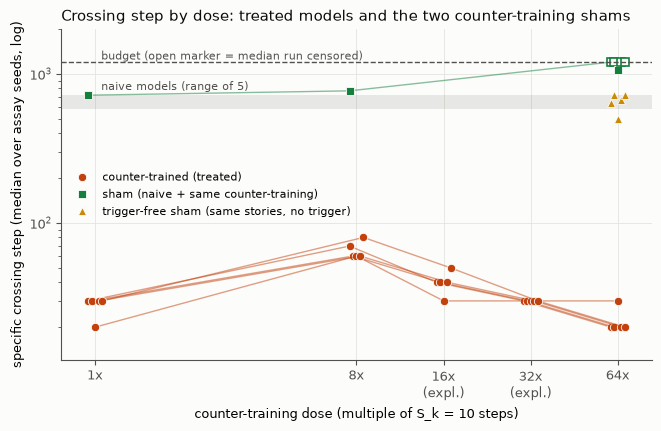

In [14]:
# Dose response: crossing step by dose, per training seed (median over 3 assay seeds), treated and sham; naive range as a band.
fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
nv = MOD.iloc[0:0]
naive_med = [float(np.median([B + 1 if v is None else v for v in tn[f"plant_lr3e-4-naive-s{k}"].values()])) for k in range(5)]
ax.axhspan(min(naive_med), max(naive_med), color=CC["naive"], alpha=0.18, lw=0)
ax.text(1.05, max(naive_med) * 1.04, "naive models (range of 5)", color=MUTED, fontsize=8, va="bottom")
jit = {0: -0.08, 1: -0.04, 2: 0.0, 3: 0.04, 4: 0.08}
for cond, mk, lab in (("counter-trained", "o", "counter-trained (treated)"), ("sham", "s", "sham (naive + same counter-training)"),
                      ("trigger-free sham", "^", "trigger-free sham (same stories, no trigger)")):
    g = MOD[MOD.condition == cond]
    for k, gk in g.groupby("train_seed"):
        gk = gk.sort_values("dose"); x = gk.dose * 2 ** jit[k]
        ax.plot(x, gk.t_median, color=CC[cond], lw=1, alpha=0.5)
        cens = gk.t_median > B
        ax.plot(x[~cens], gk.t_median[~cens], mk, color=CC[cond], ms=6, mec=SURF, mew=0.6, label=lab if k == g.train_seed.min() else None)
        ax.plot(x[cens], gk.t_median[cens], mk, mfc=SURF, mec=CC[cond], mew=1.2, ms=6)
ax.axhline(B, color=MUTED, ls="--", lw=1); ax.text(1.05, B * 1.04, "budget (open marker = median run censored)", color=MUTED, fontsize=8)
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xticks([1, 8, 16, 32, 64], ["1x", "8x", "16x\n(expl.)", "32x\n(expl.)", "64x"]); ax.set_ylim(12, 2000)
ax.set_xlabel("counter-training dose (multiple of S_k = 10 steps)"); ax.set_ylabel("specific crossing step (median over assay seeds, log)")
ax.set_title("Crossing step by dose: treated models and the two counter-training shams", loc="left", color=INK)
ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True); ax.legend(frameon=False, fontsize=8, loc="center left")
fig.savefig(ROOT / "reports/figures/phase4a_dose_response.png", dpi=150, bbox_inches="tight"); plt.show()